<a href="https://colab.research.google.com/github/leandrolaune/Inteligencia-Artificial-Clinica-Diabetes/blob/main/Intelig%C3%AAncia_Artificial_Sa%C3%BAde.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1. Importações

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

##2. Carregamento dos Dados

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

colunas = [
    "gravidez", "glicose", "pressao", "espessura_pele",
    "insulina", "imc", "pedigree", "idade", "diabetes"
]

df = pd.read_csv(url, names=colunas)

print("Shape:", df.shape)
print(df.head())

Shape: (768, 9)
   gravidez  glicose  pressao  espessura_pele  insulina   imc  pedigree  \
0         6      148       72              35         0  33.6     0.627   
1         1       85       66              29         0  26.6     0.351   
2         8      183       64               0         0  23.3     0.672   
3         1       89       66              23        94  28.1     0.167   
4         0      137       40              35       168  43.1     2.288   

   idade  diabetes  
0     50         1  
1     31         0  
2     32         1  
3     21         0  
4     33         1  


##3. Análise Exploratória

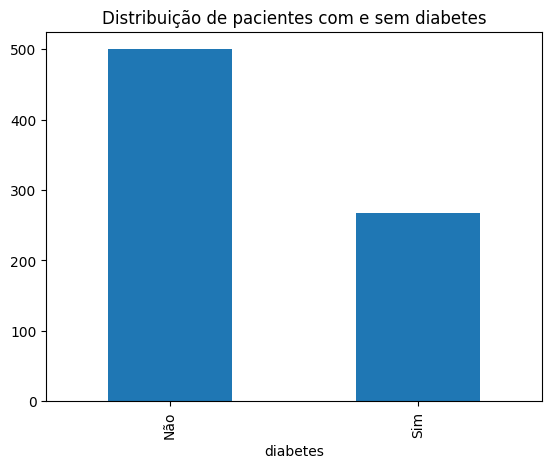

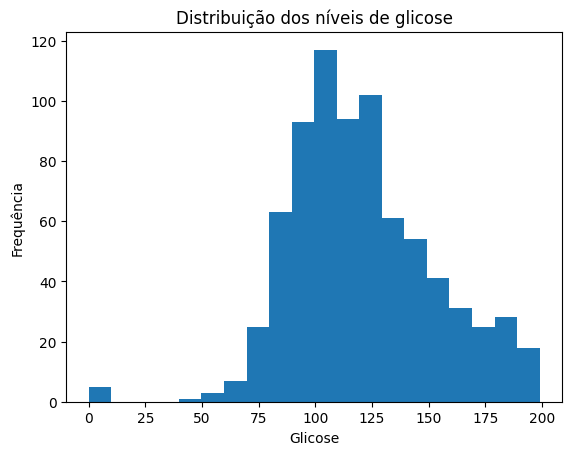

In [ ]:
# Distribuição das classes
df['diabetes'].value_counts().plot(kind='bar')
plt.title("Distribuição de pacientes com e sem diabetes")
plt.xticks([0,1], ["Não", "Sim"])
plt.show()

# Histograma da glicose
plt.hist(df['glicose'], bins=20)
plt.title("Distribuição dos níveis de glicose")
plt.xlabel("Glicose")
plt.ylabel("Frequência")
plt.show()

##4. Preparação dos Dados

In [ ]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# Normalização
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Divisão correta (IMPORTANTE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

##5. Modelo RadomForest

In [ ]:
model = RandomForestClassifier(
    n_estimators=400,#Quantidade de árvores na floresta
    max_depth=12,#Profundidade máxima de cada árvore
    min_samples_split=4,#Mínimo de amostras para dividir um nó
    min_samples_leaf=2,#Mínimo de amostras em uma folha final
    class_weight='balanced',  # melhora classes desbalanceadas automaticamente
    random_state=42
)

##6. Treinamento

In [ ]:
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=2, min_samples_split=4,
                       n_estimators=400, random_state=42)

##7. Avaliação

Acurácia: 0.7468


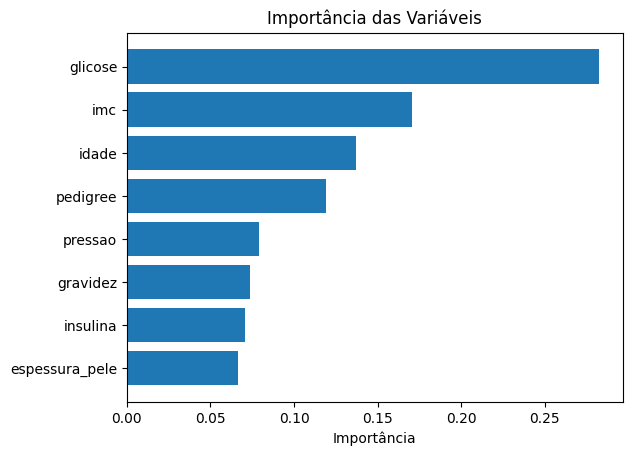

In [ ]:


from sklearn.metrics import precision_score
import matplotlib.pyplot as plt
import numpy as np

# 🔍 Predição
y_pred = model.predict(X_test)

# 🎯 Acurácia
acc = accuracy_score(y_test, y_pred)

# 🎯 Precisão (classe positiva = diabético)
prec = precision_score(y_test, y_pred)

print(f"Acurácia: {acc:.4f}")


#  IMPORTÂNCIA DAS FEATURES


importances = model.feature_importances_
features = df.drop("diabetes", axis=1).columns

# ordenar
indices = np.argsort(importances)

plt.figure()
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), features[indices])
plt.title("Importância das Variáveis")
plt.xlabel("Importância")
plt.show()

##8. Teste Interativo

In [ ]:
# =========================
# TESTE INTERATIVO (VISUAL)
# =========================

# 🔥 IMPORTS NECESSÁRIOS
import ipywidgets as widgets
from IPython.display import display, HTML

# 🎯 CAMPOS DE ENTRADA
gravidez = widgets.IntSlider(description='Gravidez', min=0, max=15, value=1)
glicose = widgets.IntSlider(description='Glicose', min=0, max=200, value=120)
pressao = widgets.IntSlider(description='Pressão', min=0, max=140, value=70)
pele = widgets.IntSlider(description='Pele', min=0, max=100, value=20)
insulina = widgets.IntSlider(description='Insulina', min=0, max=900, value=80)
imc = widgets.FloatSlider(description='IMC', min=0, max=60, value=25.0)
pedigree = widgets.FloatSlider(description='Pedigree', min=0.0, max=2.5, value=0.5)
idade = widgets.IntSlider(description='Idade', min=10, max=100, value=30)

botao = widgets.Button(description="🔍 Analisar", button_style='success')

#  FUNÇÃO DE PREDIÇÃO
def prever(b):
    dados = np.array([[
        gravidez.value,
        glicose.value,
        pressao.value,
        pele.value,
        insulina.value,
        imc.value,
        pedigree.value,
        idade.value
    ]])

    # normalizar
    dados = scaler.transform(dados)

    pred = model.predict(dados)[0]
    prob = model.predict_proba(dados)[0]

    if pred == 1:
        cor = "#ff4d4d"
        texto = "⚠️ ALTO RISCO DE DIABETES"
    else:
        cor = "#4CAF50"
        texto = "✅ BAIXO RISCO DE DIABETES"

    display(HTML(f"""
        <div style="
            padding:20px;
            border-radius:10px;
            background-color:{cor};
            color:white;
            font-size:18px;
            text-align:center;
            width:50%;
            margin-top:20px;">

            <h2>{texto}</h2>
            <p><b>Probabilidade:</b></p>
            <p>Não diabético: {prob[0]*100:.2f}%</p>
            <p>Diabético: {prob[1]*100:.2f}%</p>
        </div>
    """))

#  CONECTAR BOTÃO
botao.on_click(prever)

#  EXIBIÇÃO
display(
    widgets.VBox([
        widgets.HTML("<h3>🩺 Insira os dados do paciente</h3>"),
        gravidez, glicose, pressao, pele,
        insulina, imc, pedigree, idade,
        botao
    ])
)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
